# 02 · Preprocessing

Applies the decisions agreed after the EDA (see `docs/eda-findings.md`) and creates the train/test splits used for all modelling.

| Decision | Applied here |
|---|---|
| Fix typos (`'o'`, `'0'` → `'no'`) and drop the row with no label | yes |
| Encode categories in their natural order | yes |
| Pregnancies = 0 for male respondents | yes |
| Remove exact duplicates in Diabetes 2019 before splitting | yes |
| Keep BRFSS duplicates (real survey answers) | yes |
| Stratified 80/20 split **before** any resampling | yes |
| Imputation, scaling, BMI capping, class balancing | **no**: done inside the model pipeline on training data only |

The cleaning code lives in `src/preprocess.py` and is covered by `tests/test_preprocess.py`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src.data import load_brfss, load_diabetes_2019
from src.preprocess import (LEAKY_FEATURE, clean_diabetes_2019, overlap_between, prepare_brfss,
                            prepare_diabetes_2019, split)

PROCESSED = ROOT / 'data' / 'processed'
FIG_DIR = ROOT / 'reports' / 'figures'

## 1 · Diabetes 2019: cleaning

In [2]:
raw = load_diabetes_2019()
clean = clean_diabetes_2019(raw)
print('Raw rows:', len(raw), '→ after dropping missing target:', len(clean))
clean.head()

Raw rows: 952 → after dropping missing target: 951


,Age,Gender,Family_Diabetes,highBP,PhysicallyActive,BMI,Smoking,Alcohol,Sleep,SoundSleep,RegularMedicine,JunkFood,Stress,BPLevel,Pregancies,Pdiabetes,UriationFreq,Diabetic
0,2,1,0,1,3,39.0,0,0,8,6,0,0,1,2,0.0,0.0,0,0
1,2,1,0,1,1,28.0,0,0,8,6,1,2,1,1,0.0,0.0,0,0
2,1,1,0,0,3,24.0,0,0,6,6,0,0,1,1,0.0,0.0,0,0
3,2,1,0,0,3,23.0,0,0,8,6,0,0,1,1,0.0,0.0,0,0
4,1,1,0,0,1,27.0,0,0,8,8,0,0,1,1,0.0,0.0,0,0


A new problem found while writing the tests: **12 male respondents have 1 or 2 pregnancies recorded**. These are data-entry errors, so pregnancies is set to 0 for all male respondents.

In [3]:
pd.crosstab(raw['Gender'], raw['Pregancies'].fillna(-1)).rename(columns={-1: 'missing'})

Pregancies,missing,0.0,1.0,2.0,3.0,4.0
Gender,,,,,,
female,26,202,20,60,60,4
male,16,552,8,4,0,0


In [4]:
print('Missing values left for the pipeline to impute (training data only):')
clean.isna().sum()[clean.isna().sum() > 0]

Missing values left for the pipeline to impute (training data only):


BMI            3
Pregancies    26
Pdiabetes      1
dtype: int64

## 2 · Diabetes 2019: why duplicates must go before the split

This compares the same random 80/20 split with and without exact duplicates. `overlap` counts test rows whose answers exactly match a training row, meaning the model would be tested on something it has already seen.

In [5]:
rows = []
for label, dedup in (('Duplicates kept (as in the paper)', False), ('Duplicates removed (this project)', True)):
    X, y = prepare_diabetes_2019(raw, drop_duplicates=dedup)
    X_tr, X_te, y_tr, y_te = split(X, y)
    ov = overlap_between(X_tr, X_te)
    rows.append({'Version': label, 'Rows': len(X), 'Test rows': len(X_te),
                 'Test rows also in training': ov, 'Overlap %': round(100 * ov / len(X_te), 1)})
overlap = pd.DataFrame(rows).set_index('Version')
overlap

,Rows,Test rows,Test rows also in training,Overlap %
Version,,,,
Duplicates kept (as in the paper),951,191,181,94.8
Duplicates removed (this project),303,61,8,13.1


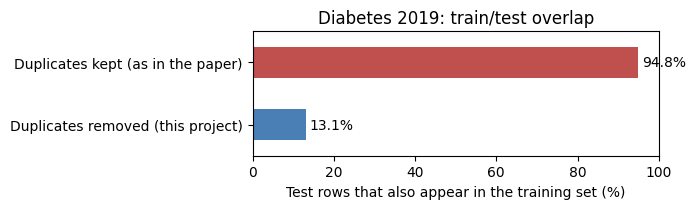

In [6]:
ax = overlap['Overlap %'].plot.barh(color=['#C0504D', '#4A7FB5'], figsize=(7, 2.2))
ax.set_xlabel('Test rows that also appear in the training set (%)'); ax.set_ylabel('')
ax.set_xlim(0, 100); ax.invert_yaxis()
for i, v in enumerate(overlap['Overlap %']):
    ax.text(v + 1, i, f'{v}%', va='center')
plt.title('Diabetes 2019: train/test overlap'); plt.tight_layout()
plt.savefig(FIG_DIR / 'prep_d19_overlap.png', dpi=200); plt.show()

With duplicates kept, almost every test row has an identical copy in the training data, so any score measures memory, not prediction. After removing duplicates, the few remaining matches are people with identical answers but **different** diagnoses. These are genuine, and a model can't get them all right.

## 3 · BRFSS: overlap check

BRFSS duplicates are kept: with 21 mostly yes/no questions, many different people give identical answers. The overlap is reported so it can be discussed in the report.

In [7]:
Xb, yb = prepare_brfss(load_brfss())
Xb_tr, Xb_te, yb_tr, yb_te = split(Xb, yb)
ov = overlap_between(Xb_tr, Xb_te)
print(f'BRFSS test rows also in training: {ov:,} of {len(Xb_te):,} ({ov / len(Xb_te):.1%})')

BRFSS test rows also in training: 6,923 of 50,736 (13.6%)


## 4 · Create and save the splits

| Name | Dataset | Target | Notes |
|---|---|---|---|
| `brfss3` | BRFSS 2015 | 3 classes | main BRFSS experiment |
| `brfss_bin` | BRFSS 2015 | diabetes vs not | fallback if prediabetes can't be predicted |
| `d19` | Diabetes 2019 | yes / no | all features, de-duplicated |
| `d19_nomed` | Diabetes 2019 | yes / no | without `RegularMedicine`, de-duplicated; used for the interface |

In [8]:
variants = {
    'brfss3': prepare_brfss(load_brfss()),
    'brfss_bin': prepare_brfss(load_brfss(), binary=True),
    'd19': prepare_diabetes_2019(raw),
    'd19_nomed': prepare_diabetes_2019(raw, drop_leaky=True),
}
summary = []
for name, (X, y) in variants.items():
    X_tr, X_te, y_tr, y_te = split(X, y)
    X_tr.assign(**{y.name: y_tr}).to_csv(PROCESSED / f'{name}_train.csv', index=False)
    X_te.assign(**{y.name: y_te}).to_csv(PROCESSED / f'{name}_test.csv', index=False)
    summary.append({'Split': name, 'Features': X.shape[1], 'Train': len(X_tr), 'Test': len(X_te),
                    'Train class %': (y_tr.value_counts(normalize=True).sort_index() * 100).round(1).to_dict(),
                    'Test class %': (y_te.value_counts(normalize=True).sort_index() * 100).round(1).to_dict()})
pd.DataFrame(summary).set_index('Split')

,Features,Train,Test,Train class %,Test class %
Split,,,,,
brfss3,21,202944,50736,"{0: 84.2, 1: 1.8, 2: 13.9}","{0: 84.2, 1: 1.8, 2: 13.9}"
brfss_bin,21,202944,50736,"{0: 86.1, 1: 13.9}","{0: 86.1, 1: 13.9}"
d19,17,242,61,"{0: 70.2, 1: 29.8}","{0: 70.5, 1: 29.5}"
d19_nomed,16,242,61,"{0: 70.2, 1: 29.8}","{0: 70.5, 1: 29.5}"


Class proportions are the same in train and test (stratified split). The test files are not used again until the final evaluation.

## Summary

- Diabetes 2019 goes from 952 raw rows to **303 unique, labelled rows** after cleaning. Fixing typos made a few more rows identical.
- Keeping duplicates would put **94.8%** of test rows in the training set as well. Removing them brings this down to 13.1% (8 rows): people with identical answers but different diagnoses.
- 12 impossible pregnancy values for men were corrected.
- Four train/test splits are saved in `data/processed/` for the modelling notebook.